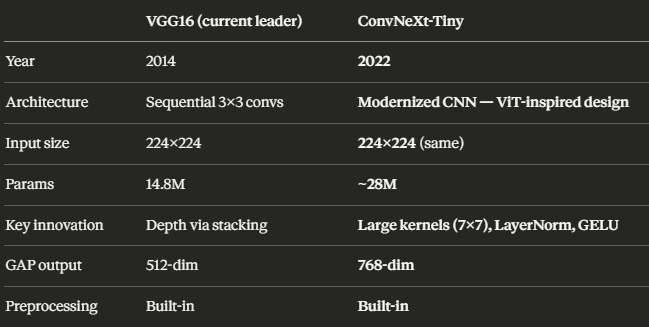

# ConvNeXt-Tiny — Amazonian Geoglyph Detection
**Model 7 of 7 — Phase 1 Classical Benchmark — The Final Model**

ConvNeXt-Tiny (2022, Meta AI) is the answer to the question:
"What if we modernized ResNet using every design trick that makes
Vision Transformers work?"

Key innovations vs all previous models:
- 7x7 depthwise convolutions (vs 3x3 in VGG/ResNet)
- Inverted bottleneck design (wider → narrow → wider)
- LayerNorm instead of BatchNorm (like ViT — no BN freeze needed)
- GELU activation instead of ReLU
- Fewer normalization layers overall
- Result: pure CNN that rivals transformers on ImageNet benchmarks

Specs:
- ~28M parameters | 224x224 input | 768-dim GAP output
- Built-in preprocessing — NO manual layer needed
- Available in keras.applications — no extra installs

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

POS_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

def count_images(folder_path):
    files = [f for f in os.listdir(folder_path)
             if os.path.splitext(f)[1].lower() in VALID_EXT]
    return len(files)

n_pos = count_images(POS_DIR)
n_neg = count_images(NEG_DIR)
print(f"Positive: {n_pos} | Negative: {n_neg} | Total: {n_pos + n_neg}")
print("Drive mounted OK")

## Step 1 — Imports & Seeds
ConvNeXtTiny imported from keras.applications.
Same SEED=42 across all 7 models for reproducible comparison.

In [ ]:
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ConvNeXtTiny
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

## Step 2 — Splits & Class Weights
Final model — identical splits to all 6 previous models.
SEED=42 guarantees same train/val/test images across the entire benchmark.

In [ ]:
POS_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
OUTPUT_DIR = "/content/outputs"
IMG_SIZE   = 224
BATCH_SIZE = 32

VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
os.makedirs(OUTPUT_DIR, exist_ok=True)

pos_files = [(str(p), 1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p), 0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath', 'label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176, stratify=train_val_df['label'], random_state=SEED)

train_df = train_df.copy(); train_df['split'] = 'train'
val_df   = val_df.copy();   val_df['split']   = 'val'
test_df  = test_df.copy();  test_df['split']  = 'test'

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_df['label'].values)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Class weights -> Neg: {class_weight_dict[0]:.4f} | Pos: {class_weight_dict[1]:.4f}")